In [1]:
!pip install qiskit qiskit-aer pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 44.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 38.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 36.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.9 MB/s eta 0:00:00


In [2]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

print("Qiskit Quantum Gate Simulation Project")
print("Libraries imported successfully!")

Qiskit Quantum Gate Simulation Project
Libraries imported successfully!



1. Pauli-X Gate
     ┌───┐┌─┐
  q: ┤ X ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 
Measurement Results: {'1': 1000}

2. Pauli-Y Gate
     ┌───┐┌─┐
  q: ┤ Y ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 
Measurement Results: {'1': 1000}

3. Pauli-Z Phase Demonstration
     ┌───┐┌───┐┌───┐┌─┐
  q: ┤ H ├┤ Z ├┤ H ├┤M├
     └───┘└───┘└───┘└╥┘
c: 1/════════════════╩═
                     0 
Measurement Results: {'1': 1000}

4. Hadamard Gate
     ┌───┐┌─┐
  q: ┤ H ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 
Measurement Results: {'1': 499, '0': 501}

5. CNOT Gate
     ┌───┐     ┌─┐   
q_0: ┤ X ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 
Measurement Results: {'11': 1000}

6. Bell State Circuit
     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 
Measurement Results: {'00': 510, '11': 490}

STATEVECTOR ANALYSIS


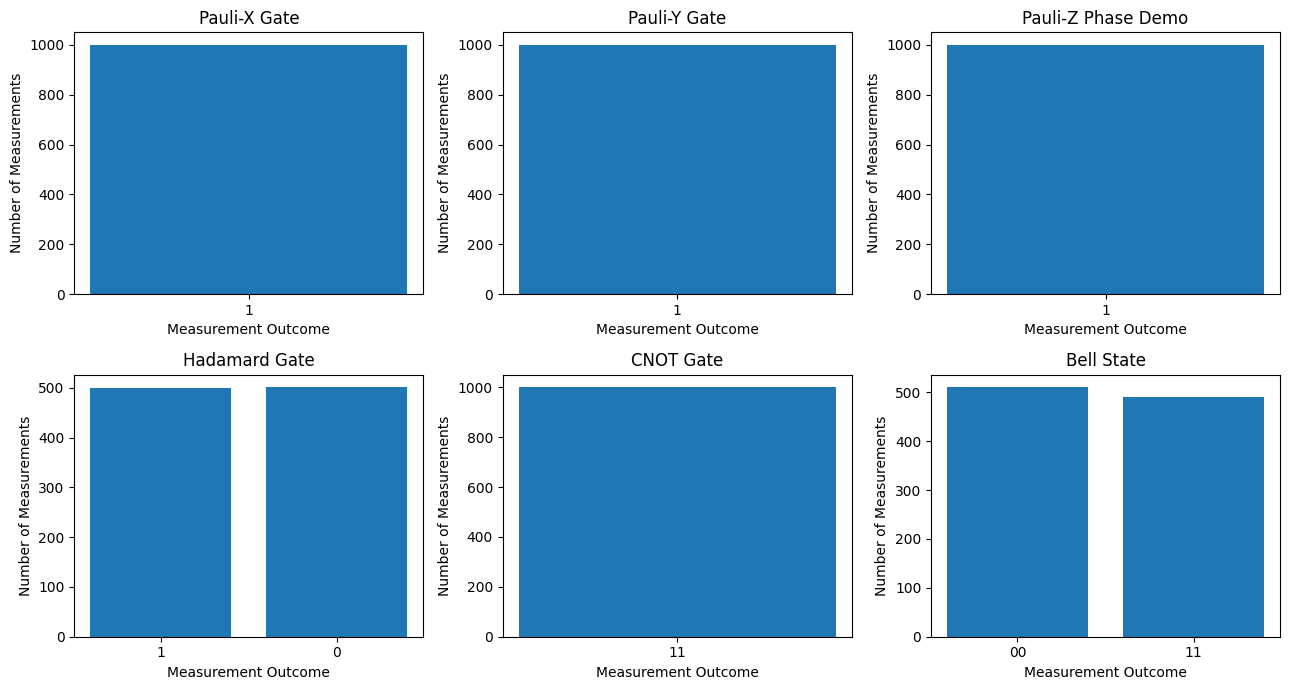


PROJECT EXECUTION COMPLETED
Quantum gates implemented: X, Y, Z, H, CNOT
Bell state circuit implemented successfully.
Measurement results and graphs generated.
Statevector analysis completed.


In [7]:
# =====================================================
# PROJECT: QISKIT IMPLEMENTATION OF QUANTUM GATES
# Platform: Google Colab
# Language: Python
# =====================================================

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector
import matplotlib.pyplot as plt

# Initialize quantum simulator
simulator = AerSimulator()

# Store results of all experiments
all_results = {}


# Function to execute a quantum circuit
def run_experiment(name, circuit, shots=1000):

    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    # Display circuit
    print(circuit.draw(output="text"))

    # Compile circuit
    compiled_circuit = transpile(circuit, simulator)

    # Run simulation
    job = simulator.run(compiled_circuit, shots=shots)

    # Obtain measurement results
    result = job.result()
    counts = result.get_counts()

    all_results[name] = counts

    print("Measurement Results:", counts)

    return counts


# -----------------------------------------------------
# 1. PAULI-X GATE
# |0> -> |1>
# -----------------------------------------------------

qc_x = QuantumCircuit(1, 1)

qc_x.x(0)
qc_x.measure(0, 0)

counts_x = run_experiment("1. Pauli-X Gate", qc_x)


# -----------------------------------------------------
# 2. PAULI-Y GATE
# |0> -> i|1>
# -----------------------------------------------------

qc_y = QuantumCircuit(1, 1)

qc_y.y(0)
qc_y.measure(0, 0)

counts_y = run_experiment("2. Pauli-Y Gate", qc_y)


# -----------------------------------------------------
# 3. PAULI-Z PHASE DEMONSTRATION
# H -> Z -> H
# |0> -> |1>
# -----------------------------------------------------

qc_z = QuantumCircuit(1, 1)

qc_z.h(0)
qc_z.z(0)
qc_z.h(0)
qc_z.measure(0, 0)

counts_z = run_experiment("3. Pauli-Z Phase Demonstration", qc_z)


# -----------------------------------------------------
# 4. HADAMARD GATE
# Creates equal superposition
# -----------------------------------------------------

qc_h = QuantumCircuit(1, 1)

qc_h.h(0)
qc_h.measure(0, 0)

counts_h = run_experiment("4. Hadamard Gate", qc_h)


# -----------------------------------------------------
# 5. CNOT GATE
# Control qubit = 1
# Target qubit flips from 0 to 1
# -----------------------------------------------------

qc_cnot = QuantumCircuit(2, 2)

qc_cnot.x(0)
qc_cnot.cx(0, 1)
qc_cnot.measure([0, 1], [0, 1])

counts_cnot = run_experiment("5. CNOT Gate", qc_cnot)


# -----------------------------------------------------
# 6. BELL STATE CIRCUIT
# Demonstrates quantum entanglement
# -----------------------------------------------------

qc_bell = QuantumCircuit(2, 2)

qc_bell.h(0)
qc_bell.cx(0, 1)
qc_bell.measure([0, 1], [0, 1])

counts_bell = run_experiment("6. Bell State Circuit", qc_bell)


# -----------------------------------------------------
# STATEVECTOR ANALYSIS
# -----------------------------------------------------

print("\n" + "=" * 50)
print("STATEVECTOR ANALYSIS")
print("=" * 50)


# Pauli-X statevector
circ_x = QuantumCircuit(1)
circ_x.x(0)

state_x = Statevector.from_instruction(circ_x)

print("Pauli-X Statevector:", state_x.data)


# Pauli-Y statevector
circ_y = QuantumCircuit(1)
circ_y.y(0)

state_y = Statevector.from_instruction(circ_y)

print("Pauli-Y Statevector:", state_y.data)


# Pauli-Z phase demonstration: H-Z-H
z_state_circuit = QuantumCircuit(1)

z_state_circuit.h(0)
z_state_circuit.z(0)
z_state_circuit.h(0)

state_z = Statevector.from_instruction(z_state_circuit)

print("H-Z-H Statevector:", state_z.data)


# Hadamard statevector
circ_h = QuantumCircuit(1)
circ_h.h(0)

state_h = Statevector.from_instruction(circ_h)

print("Hadamard Statevector:", state_h.data)


# -----------------------------------------------------
# PLOT MEASUREMENT RESULTS
# -----------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(13, 7))

experiments = [
    ("Pauli-X Gate", counts_x),
    ("Pauli-Y Gate", counts_y),
    ("Pauli-Z Phase Demo", counts_z),
    ("Hadamard Gate", counts_h),
    ("CNOT Gate", counts_cnot),
    ("Bell State", counts_bell)
]

for ax, (name, counts) in zip(axes.flat, experiments):

    states = list(counts.keys())
    frequencies = list(counts.values())

    ax.bar(states, frequencies)
    ax.set_title(name)
    ax.set_xlabel("Measurement Outcome")
    ax.set_ylabel("Number of Measurements")

plt.tight_layout()
plt.show()


# -----------------------------------------------------
# FINAL PROJECT SUMMARY
# -----------------------------------------------------

print("\n" + "=" * 50)
print("PROJECT EXECUTION COMPLETED")
print("=" * 50)

print("Quantum gates implemented: X, Y, Z, H, CNOT")
print("Bell state circuit implemented successfully.")
print("Measurement results and graphs generated.")
print("Statevector analysis completed.")